# Tugas Praktikum 5: Sequential Pattern Analysis
**Nama:** Hilal Tsabitul Azmi Arba'i  |  **NRP:** 5054251008

**Dataset:** Online Retail (UCI). **Algoritma:** PrefixSpan (varian itemset, diimplementasikan sendiri karena pustaka `prefixspan` hanya mendukung urutan item tunggal, bukan itemset per invoice).

**Alur:** impor data, eksplorasi dan pembersihan, penyusunan sequence per pelanggan, PrefixSpan, evaluasi (support, confidence), kesimpulan.

## 1. Import Library dan Dataset

In [1]:
import time
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 60)

In [2]:
df = pd.read_excel("OnlineRetail.xlsx")   # file dataset ada di folder yang sama (tidak diunggah ke GitHub)
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Shape:", df.shape)
df.info()

Shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 2. Eksplorasi dan Pembersihan Data

**Kolom yang relevan** untuk pola berurutan:
- `CustomerID`: identitas pelanggan, satu pelanggan = satu sequence
- `InvoiceDate`: menentukan urutan waktu pembelian
- `InvoiceNo`: menentukan item mana yang dibeli bersamaan (satu invoice = satu itemset)
- `Description`: item yang dibeli

Kolom lain (`StockCode`, `Quantity`, `UnitPrice`, `Country`) dipakai untuk pembersihan saja.

Pertama, lihat kondisi data mentah.

In [4]:
print("Missing value per kolom:")
display(df.isnull().sum())
print("Invoice dibatalkan (diawali 'C'):", df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Quantity <= 0                    :", (df["Quantity"] <= 0).sum())

Missing value per kolom:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Invoice dibatalkan (diawali 'C'): 9288
Quantity <= 0                    : 10624


Pembersihan sesuai ketentuan: hapus `Description` kosong, invoice batal (diawali "C"), `Quantity` <= 0, dan `CustomerID` kosong. Selain itu, `Description` dinormalkan (huruf besar, tanpa spasi berlebih) agar produk yang sama tidak terhitung berbeda. Ringkasan sebelum dan sesudah ditampilkan sebagai tabel.

In [5]:
def ringkasan(d):
    return {"Jumlah baris": len(d), "Jumlah invoice": d["InvoiceNo"].nunique(), "Jumlah pelanggan": d["CustomerID"].nunique()}

sebelum = ringkasan(df)

d = df.dropna(subset=["Description"])
d = d[~d["InvoiceNo"].astype(str).str.startswith("C")]
d = d[d["Quantity"] > 0]
d = d.dropna(subset=["CustomerID"]).copy()
d["Description"] = d["Description"].str.strip().str.upper()

sesudah = ringkasan(d)
tabel = pd.DataFrame({"Sebelum": sebelum, "Sesudah": sesudah})
tabel["Dihapus"] = tabel["Sebelum"] - tabel["Sesudah"]
display(tabel)

,Sebelum,Sesudah,Dihapus
Jumlah baris,541909,397924,143985
Jumlah invoice,25900,18536,7364
Jumlah pelanggan,4372,4339,33


Visualisasi singkat data yang sudah bersih: 10 produk terpopuler, transaksi per bulan, dan distribusi jumlah invoice per pelanggan.

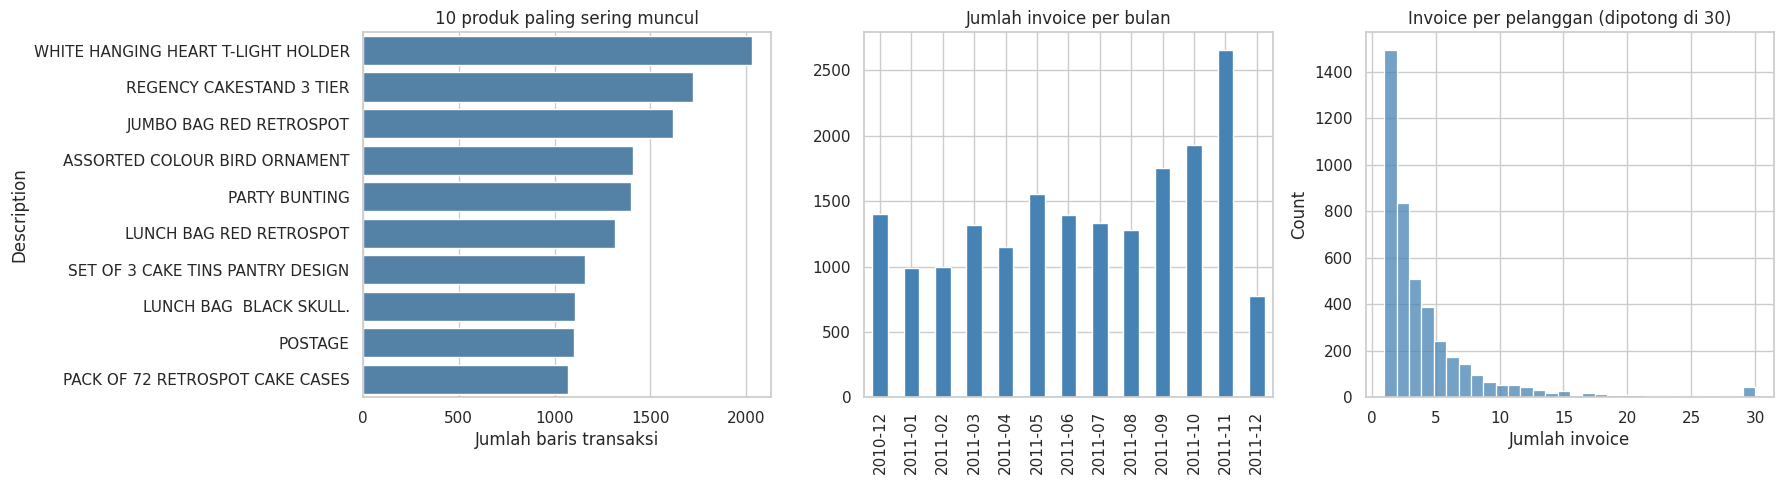

Pelanggan dengan hanya 1 invoice: 1494 (34.4%)
Median invoice per pelanggan: 2.0


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

top = d["Description"].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, ax=axes[0], color="steelblue")
axes[0].set_title("10 produk paling sering muncul"); axes[0].set_xlabel("Jumlah baris transaksi")

bulan = d.groupby(d["InvoiceDate"].dt.to_period("M"))["InvoiceNo"].nunique()
bulan.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Jumlah invoice per bulan"); axes[1].set_xlabel("")

per_cust = d.groupby("CustomerID")["InvoiceNo"].nunique()
sns.histplot(per_cust.clip(upper=30), bins=30, ax=axes[2], color="steelblue")
axes[2].set_title("Invoice per pelanggan (dipotong di 30)"); axes[2].set_xlabel("Jumlah invoice")

plt.tight_layout(); plt.show()
print("Pelanggan dengan hanya 1 invoice:", (per_cust == 1).sum(), f"({(per_cust == 1).mean():.1%})")
print("Median invoice per pelanggan:", per_cust.median())

## 3. Persiapan Data untuk Sequential Pattern Mining

1. Item dalam satu `InvoiceNo` digabung menjadi satu **itemset** (set unik, urut abjad).
2. Invoice diurutkan per pelanggan menurut `InvoiceDate` (dan `InvoiceNo` bila waktunya sama).
3. Setiap pelanggan menjadi satu **sequence**: list of list, yaitu `[[itemset_invoice_1], [itemset_invoice_2], ...]`.

Pelanggan yang hanya punya satu invoice tetap dipertahankan: mereka tetap dihitung dalam penyebut support (relatif terhadap jumlah pelanggan) walaupun tidak bisa membentuk pola dengan dua langkah.

In [7]:
invoice = (d.sort_values(["CustomerID", "InvoiceDate", "InvoiceNo"])
             .groupby(["CustomerID", "InvoiceNo"], sort=False)
             .agg(waktu=("InvoiceDate", "min"), item=("Description", lambda s: sorted(set(s))))
             .reset_index()
             .sort_values(["CustomerID", "waktu", "InvoiceNo"]))

sequences = invoice.groupby("CustomerID")["item"].apply(list)    # satu sequence per pelanggan
print("Jumlah sequence (pelanggan):", len(sequences))
print("Rata-rata itemset (invoice) per sequence:", round(sequences.map(len).mean(), 2))
print("Rata-rata item per itemset:", round(invoice["item"].map(len).mean(), 2))

# contoh sequence satu pelanggan (3 invoice pertama, 4 item pertama per invoice)
idx = next(i for i, s in enumerate(sequences) if 3 <= len(s) <= 6)    # pelanggan pertama dengan 3-6 invoice
contoh = sequences.iloc[idx]
print("\nContoh pelanggan", sequences.index[idx], "->", len(contoh), "invoice")
for i, its in enumerate(contoh[:3], 1):
    print(f"  invoice ke-{i} ({len(its)} item):", its[:3], "..." if len(its) > 3 else "")

Jumlah sequence (pelanggan): 4339
Rata-rata itemset (invoice) per sequence: 4.27
Rata-rata item per itemset: 20.92

Contoh pelanggan 12348.0 -> 4 invoice
  invoice ke-1 (13 item): ['60 CAKE CASES DOLLY GIRL DESIGN', '60 CAKE CASES VINTAGE CHRISTMAS', '60 TEATIME FAIRY CAKE CASES'] ...
  invoice ke-2 (6 item): ['MULTI HEARTS  STICKERS', 'PACK OF 12 BLUE PAISLEY TISSUES', 'PACK OF 12 HEARTS DESIGN TISSUES'] ...
  invoice ke-3 (5 item): ['DOUGHNUT LIP GLOSS', 'ICE CREAM PEN LIP GLOSS', 'ICE CREAM SUNDAE LIP GLOSS'] ...


Agar mining cepat, nama produk diubah menjadi ID integer (`vocab`). Hasil akhir diterjemahkan kembali ke nama produk.

In [8]:
vocab = {}
for s in sequences:
    for itemset in s:
        for x in itemset:
            vocab.setdefault(x, len(vocab))
inv_vocab = {i: x for x, i in vocab.items()}

seq_db = [[tuple(sorted(vocab[x] for x in itemset)) for itemset in s] for s in sequences]
print("Jumlah produk unik:", len(vocab))
print("Panjang sequence terpanjang:", max(map(len, seq_db)), "invoice")

Jumlah produk unik: 3866
Panjang sequence terpanjang: 210 invoice


## 4. Penerapan Algoritma PrefixSpan

**Cara kerja singkat:** mulai dari item yang frequent, lalu perpanjang pola langkah demi langkah dengan dua cara:
- **S-extension**: tambah itemset baru sesudahnya (item dibeli pada invoice yang lebih lambat), contoh `{A} -> {B}`
- **I-extension**: tambah item ke itemset terakhir (dibeli dalam invoice yang sama), contoh `{A, B}`

Hanya database terproyeksi (bagian sequence setelah pola) yang dipindai di tiap langkah, dan pola yang support-nya di bawah ambang langsung dipangkas. Support = proporsi **pelanggan** yang sequence-nya memuat pola tersebut (tiap pelanggan dihitung sekali).

Implementasi:

In [9]:
from collections import defaultdict
import numpy as np

def mine_sequences(sequences, minsup, maxlen=None):
    """PrefixSpan (varian itemset) -> dict {pattern: jumlah_pelanggan}.
    sequences: list[list[tuple(item_id,...)]], item dalam tiap itemset terurut naik.
    pattern  : tuple of tuple, mis. ((3,), (5, 9)) = {3} lalu {5,9}."""
    N = len(sequences)
    ms = int(np.ceil(minsup * N))
    cnt = defaultdict(int)
    for s in sequences:
        for x in {x for e in s for x in e}:
            cnt[x] += 1
    freq = {x for x, c in cnt.items() if c >= ms}
    seq = [[tuple(x for x in e if x in freq) for e in s] for s in sequences]
    seq = [[e for e in s if e] for s in seq]
    res = {}

    def mine(pattern, last_item, plen, proj):
        s_cnt, i_cnt = defaultdict(dict), defaultdict(dict)
        for sid, ends in proj:
            s = seq[sid]
            loc = defaultdict(list)
            for e in range(ends[0] + 1, len(s)):
                for x in s[e]:
                    loc[x].append(e)
            for x, l in loc.items():
                s_cnt[x][sid] = l
            loc = defaultdict(list)
            for e in ends:
                for x in s[e]:
                    if x > last_item:
                        loc[x].append(e)
            for x, l in loc.items():
                i_cnt[x][sid] = l
        if maxlen is not None and plen >= maxlen:
            return
        for kind, cands in (("i", i_cnt), ("s", s_cnt)):
            for x, d in cands.items():
                if len(d) < ms:
                    continue
                newp = pattern[:-1] + (pattern[-1] + (x,),) if kind == "i" else pattern + ((x,),)
                res[newp] = len(d)
                mine(newp, x, plen + 1, list(d.items()))

    root = defaultdict(dict)
    for sid, s in enumerate(seq):
        for e, el in enumerate(s):
            for x in el:
                root[x].setdefault(sid, []).append(e)
    for x, d in root.items():
        if len(d) >= ms:
            res[((x,),)] = len(d)
            mine(((x,),), x, 1, list(d.items()))
    return res


### Pemilihan minimum support
Ketentuan: mulai dari 0,01. Kita coba beberapa nilai untuk melihat jumlah pola dan waktu komputasinya. Panjang pola dibatasi `maxlen = 2` (maksimal 2 itemset/invoice berurutan) agar waktu komputasi wajar dan pola mudah ditafsirkan. Sebagai pembanding hasil uji coba terpisah pada min_support 0,01: `maxlen = 3` menghasilkan 59.121 pola dalam 518 detik, sedangkan `maxlen = 4` belum selesai dalam 15 menit.

In [10]:
hasil_uji, simpan = [], {}
for ms in [0.05, 0.03, 0.02, 0.01]:
    t0 = time.time()
    r = mine_sequences(seq_db, ms, maxlen=2)
    simpan[ms] = r
    seq_pola = sum(1 for p in r if len(p) >= 2)
    hasil_uji.append({"min_support": ms, "min_pelanggan": int(np.ceil(ms * len(seq_db))),
                      "total_pola": len(r), "pola_berurutan(>=2 itemset)": seq_pola,
                      "waktu_detik": round(time.time() - t0, 1)})
display(pd.DataFrame(hasil_uji))

,min_support,min_pelanggan,total_pola,pola_berurutan(>=2 itemset),waktu_detik
0,0.05,217,304,8,3.2
1,0.03,131,1184,281,17.2
2,0.02,87,3419,1506,48.5
3,0.01,44,22851,15707,255.6


**Keputusan:** `min_support = 0.01` dan `maxlen = 2` (lihat tabel di atas dan penjelasan pada kesimpulan). Nilai 0,01 setara minimal sekitar 44 pelanggan.

In [11]:
MINSUP = 0.01
MAXLEN = 2   # maksimum jumlah itemset (invoice) dalam satu pola

N = len(seq_db)
pola = simpan[MINSUP]     # hasil dari percobaan di atas (tidak dihitung ulang)
print(f"Pola ditemukan: {len(pola)}")

Pola ditemukan: 22851


## 5. Evaluasi Pola Berurutan

Metrik untuk pola P dengan awalan A (P tanpa item terakhir) dan konsekuen C (item terakhir):
- **Support(P)** = pelanggan yang memuat P / total pelanggan
- **Confidence(A -> C)** = support(P) / support(A): dari pelanggan yang sudah mengikuti A, berapa persen yang kemudian membeli C
- **Lift** = confidence / support(C): berapa kali lebih besar dari peluang membeli C secara acak. Lift > 1 berarti ada keterkaitan, bukan sekadar C yang populer.

Pola dengan satu item saja tidak punya confidence, sehingga hanya dipakai sebagai penyebut.

In [12]:
def nama(itemset):
    return "{" + ", ".join(inv_vocab[i] for i in itemset) + "}"

def tampil(pattern):
    return " -> ".join(nama(e) for e in pattern)

def awalan(pattern):
    """pola tanpa item terakhir"""
    *depan, terakhir = pattern
    if len(terakhir) > 1:
        return tuple(depan) + (terakhir[:-1],)
    return tuple(depan)

rows = []
for p, c in pola.items():
    n_item = sum(len(e) for e in p)
    if n_item < 2:
        continue
    a = awalan(p)
    konsekuen = p[-1][-1]
    sup = c / N
    conf = c / pola[a]
    lift = conf / (pola[((konsekuen,),)] / N)
    rows.append({"pola": tampil(p), "n_itemset": len(p), "n_item": n_item,
                 "pelanggan": c, "support": sup, "confidence": conf, "lift": lift,
                 "antecedent": tampil(a), "consequent": inv_vocab[konsekuen]})
hasil = pd.DataFrame(rows).sort_values(["support", "confidence"], ascending=False).reset_index(drop=True)
print("Pola dengan >= 2 item:", len(hasil))
print("  - berurutan lintas invoice (>= 2 itemset):", (hasil["n_itemset"] >= 2).sum())
print("  - kombinasi dalam satu invoice (1 itemset):", (hasil["n_itemset"] == 1).sum())

Pola dengan >= 2 item: 21088
  - berurutan lintas invoice (>= 2 itemset): 15707
  - kombinasi dalam satu invoice (1 itemset): 5381


### Pola berurutan teratas (lintas invoice, >= 2 itemset) menurut support

In [13]:
seq_only = hasil[hasil["n_itemset"] >= 2]
display(seq_only[["pola", "pelanggan", "support", "confidence", "lift"]].head(15).style.format({"support": "{:.3f}", "confidence": "{:.3f}", "lift": "{:.2f}"}))

,pola,pelanggan,support,confidence,lift
0,{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER},405,0.093,0.473,2.40
1,{REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER},330,0.076,0.375,1.84
3,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT},312,0.072,0.491,3.36
5,{ASSORTED COLOUR BIRD ORNAMENT} -> {ASSORTED COLOUR BIRD ORNAMENT},291,0.067,0.429,2.75
7,{PARTY BUNTING} -> {PARTY BUNTING},280,0.065,0.395,2.42
8,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT},276,0.064,0.519,4.23
29,{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG BLACK SKULL.},229,0.053,0.500,4.74
32,{SET OF 3 CAKE TINS PANTRY DESIGN} -> {SET OF 3 CAKE TINS PANTRY DESIGN},225,0.052,0.352,2.38
41,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.},212,0.049,0.398,3.78
45,{LUNCH BAG CARS BLUE} -> {LUNCH BAG RED RETROSPOT},209,0.048,0.436,3.56


### Tiga pola terbaik (support tertinggi)
Hanya pola yang benar-benar berurutan (melibatkan minimal dua invoice berbeda) yang dipertimbangkan. Dua jenis dipisah: pembelian ulang item yang sama, dan urutan dua produk berbeda.

In [14]:
top3 = seq_only.head(3)
display(top3[["pola", "pelanggan", "support", "confidence", "lift"]].style.format({"support": "{:.3f}", "confidence": "{:.3f}", "lift": "{:.2f}"}))

print("\nTop 3 untuk urutan dua produk BERBEDA:")
beda = seq_only[seq_only.apply(lambda r: r["antecedent"] != "{" + r["consequent"] + "}", axis=1)]
display(beda[["pola", "pelanggan", "support", "confidence", "lift"]].head(3).style.format({"support": "{:.3f}", "confidence": "{:.3f}", "lift": "{:.2f}"}))

,pola,pelanggan,support,confidence,lift
0,{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER},405,0.093,0.473,2.40
1,{REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER},330,0.076,0.375,1.84
3,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT},312,0.072,0.491,3.36



Top 3 untuk urutan dua produk BERBEDA:


,pola,pelanggan,support,confidence,lift
41,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.},212,0.049,0.398,3.78
45,{LUNCH BAG CARS BLUE} -> {LUNCH BAG RED RETROSPOT},209,0.048,0.436,3.56
46,{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG RED RETROSPOT},208,0.048,0.454,3.70


### Visualisasi

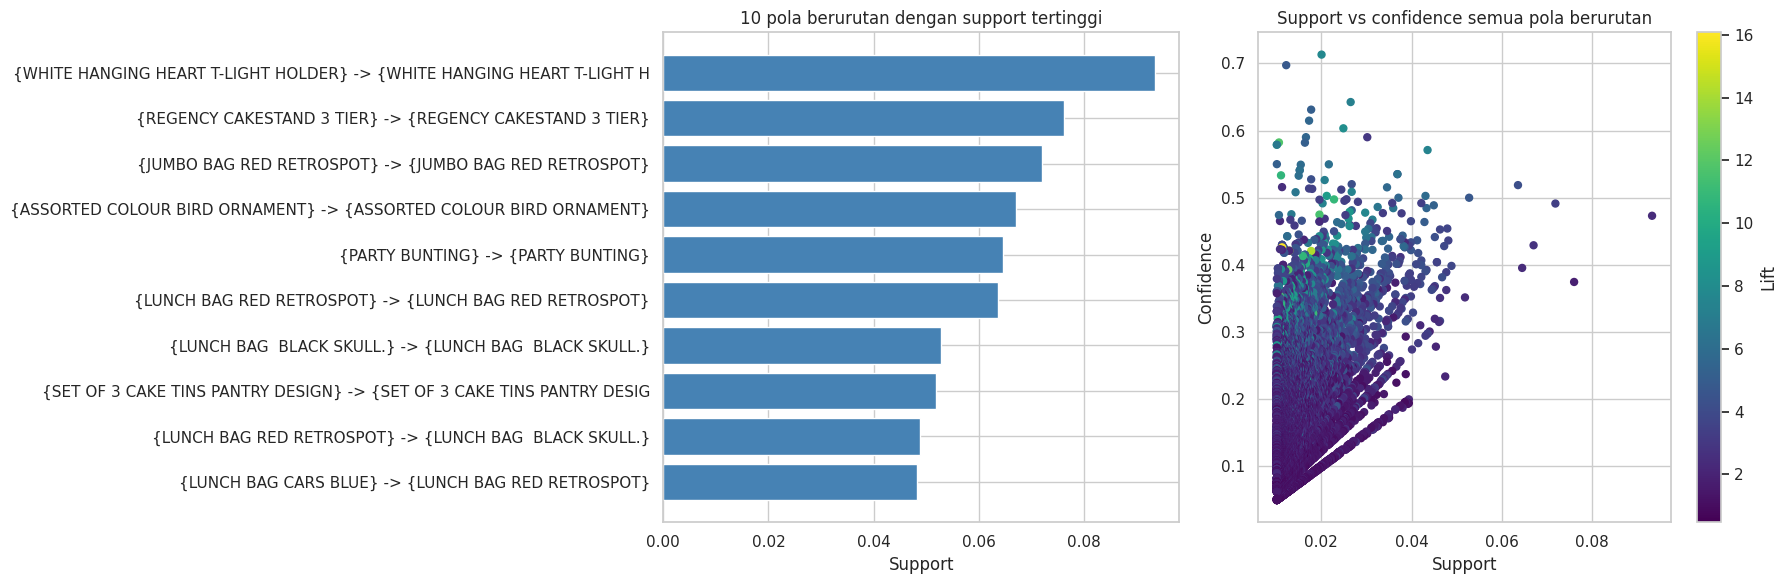

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
t = seq_only.head(10).iloc[::-1]
axes[0].barh([x[:70] for x in t["pola"]], t["support"], color="steelblue")
axes[0].set_title("10 pola berurutan dengan support tertinggi"); axes[0].set_xlabel("Support")

sc = axes[1].scatter(seq_only["support"], seq_only["confidence"], c=seq_only["lift"], cmap="viridis", s=25)
plt.colorbar(sc, ax=axes[1], label="Lift")
axes[1].set_xlabel("Support"); axes[1].set_ylabel("Confidence"); axes[1].set_title("Support vs confidence semua pola berurutan")
plt.tight_layout(); plt.show()

Pola dengan confidence tertinggi (cukup sering muncul) untuk melihat prediksi pembelian berikutnya yang paling kuat:

In [16]:
display(seq_only.sort_values(["confidence", "support"], ascending=False)[["pola", "pelanggan", "support", "confidence", "lift"]].head(10)
        .style.format({"support": "{:.3f}", "confidence": "{:.3f}", "lift": "{:.2f}"}))

,pola,pelanggan,support,confidence,lift
2267,{LUNCH BAG SUKI DESIGN} -> {LUNCH BAG SUKI DESIGN},87,0.020,0.713,7.75
11207,{JUMBO BAG SCANDINAVIAN PAISLEY} -> {JUMBO BAG RED RETROSPOT},53,0.012,0.697,4.77
825,{ALARM CLOCK BAKELIKE ORANGE} -> {ALARM CLOCK BAKELIKE RED},115,0.027,0.642,7.18
3500,{LUNCH BAG SUKI DESIGN} -> {LUNCH BAG RED RETROSPOT},77,0.018,0.631,5.15
3799,{LUNCH BAG SUKI DESIGN} -> {LUNCH BAG CARS BLUE},75,0.017,0.615,5.57
1051,{ALARM CLOCK BAKELIKE ORANGE} -> {ALARM CLOCK BAKELIKE GREEN},108,0.025,0.603,8.13
4303,{LUNCH BAG SUKI DESIGN} -> {LUNCH BAG BLACK SKULL.},72,0.017,0.590,5.59
511,{CANDLEHOLDER PINK HANGING HEART} -> {WHITE HANGING HEART T-LIGHT HOLDER},131,0.030,0.590,2.99
17334,{BREAD BIN DINER STYLE MINT} -> {BREAD BIN DINER STYLE IVORY},46,0.011,0.582,11.81
4493,{LUNCH BAG SUKI DESIGN} -> {LUNCH BAG SPACEBOY DESIGN},71,0.016,0.582,5.15


## 6. Interpretasi dan Kesimpulan

### Tiga pola terbaik (support tertinggi, pola berurutan lintas invoice)
| No | Pola | Support | Confidence | Lift |
|---|---|---|---|---|
| 1 | {WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER} | 0,093 (405 pelanggan) | 0,473 | 2,40 |
| 2 | {REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER} | 0,076 (330 pelanggan) | 0,375 | 1,84 |
| 3 | {JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT} | 0,072 (312 pelanggan) | 0,491 | 3,36 |

**Makna bisnis:**
1. **Pembelian ulang T-light holder.** Sekitar 9,3% pelanggan membeli produk ini pada minimal dua invoice berbeda, dan hampir separuh (47%) dari yang pernah membelinya membeli lagi di invoice berikutnya. Lift 2,4 artinya peluangnya 2,4 kali lebih tinggi daripada pelanggan acak. Produk ini cocok untuk program *repeat order*, misalnya pengingat atau diskon pembelian ulang, dan stoknya perlu dijaga.
2. **Pembelian ulang cake stand.** Pola serupa dengan konfirmasi lebih rendah (confidence 37,5%, lift 1,84). Karena ini barang tahan lama, pembelian ulang kemungkinan berasal dari pelanggan grosir/reseller yang mengisi stok, bukan konsumen akhir.
3. **Pembelian ulang jumbo bag.** Confidence tertinggi di antara tiga besar (49%) dan lift 3,36. Tas adalah produk dengan banyak varian, jadi pembelian berikutnya sering berupa model yang sama.

Ketiga pola teratas semuanya berupa **pembelian ulang item yang sama**. Ini wajar: produk terlaris punya peluang besar muncul lagi, dan pelanggan toko ini sebagian besar pedagang grosir yang memesan berulang.

### Urutan dua produk berbeda (lebih informatif untuk rekomendasi)
- {LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.}: support 0,049, confidence 0,398, lift 3,78
- {LUNCH BAG CARS BLUE} -> {LUNCH BAG RED RETROSPOT}: support 0,048, confidence 0,436, lift 3,56
- {LUNCH BAG BLACK SKULL.} -> {LUNCH BAG RED RETROSPOT}: support 0,048, confidence 0,454, lift 3,70

Pelanggan cenderung **melengkapi koleksi** varian desain yang sama (lunch bag) pada pesanan berikutnya. Pola dengan confidence lebih tinggi tetapi support lebih rendah juga muncul pada tabel confidence tertinggi, misalnya {ALARM CLOCK BAKELIKE ORANGE} -> {ALARM CLOCK BAKELIKE RED} (confidence 0,64, lift 7,2) dan {BREAD BIN DINER STYLE MINT} -> {BREAD BIN DINER STYLE IVORY} (confidence 0,58, lift 11,8). Ini kandidat untuk rekomendasi "lengkapi warna lain" pada pesanan lanjutan.

### Kesimpulan
1. Setelah pembersihan, tersisa 397.924 baris, 18.536 invoice, dan 4.339 pelanggan. Pelanggan dengan satu invoice hanya (34%) tidak bisa membentuk pola berurutan, tetapi tetap dihitung di penyebut support.
2. Pada `min_support = 0,01` (minimal 44 pelanggan) ditemukan 22.851 pola, 15.707 di antaranya berurutan lintas invoice. Nilai awal 0,01 dipertahankan karena menghasilkan pola yang cukup beragam. Nilai 0,05 hanya menghasilkan 8 pola berurutan (terlalu sedikit), sedangkan di bawah 0,01 jumlah pola dan waktu komputasi meningkat tajam. Panjang pola dibatasi 2 itemset karena `maxlen = 3` menghasilkan 59 ribu pola dengan waktu >8 menit dan `maxlen = 4` tidak selesai dalam 15 menit.
3. Pola berurutan paling sering adalah **pembelian ulang produk yang sama**, lalu **urutan antar varian dalam satu keluarga produk** (lunch bag, jam alarm, bread bin, jumbo bag).
4. Confidence dan lift tinggi pada keluarga produk yang sama menunjukkan bahwa rekomendasi berbasis urutan paling efektif untuk *varian/koleksi* produk, bukan antar kategori berbeda.
5. **Keterbatasan:** pola dihitung per pelanggan dan tidak mempertimbangkan jarak waktu antar pembelian (pembelian berselang 1 minggu dan 11 bulan dianggap sama), pembatasan panjang pola menyisakan pola yang lebih panjang tidak tergali, dan sebagian besar pelanggan adalah pedagang grosir sehingga hasil belum tentu berlaku untuk konsumen ritel biasa.